# 11 — What-if scenarios and step-edge price errors

**Does:** (A) pushes four shocks through the dispatch model for every day of 2024 (demand +5%, a drought year, a low-wind monsoon, a coal shortage, and all four together) and measures how prices, costs and tightness respond. (B) checks how much worse Stage 5's price forecasts are on days when demand sits near a coal-tier step.

**Question:** how fragile are prices, and which shocks create the tight days where market power (Part 3) would bite?

**Input:** `india_electricity_data_updated.csv`, `availability_daily.csv`, `dispatch_weather_*_daily.csv` (the base case), `price_forecast_test.csv` (Stage 5)

**Output:** `data/processed/scenario_results.csv`

**Code:** `src/availability.py` (`scale_availability`), `src/dispatch.py`, `src/forecast.py`

**Logged in:** `docs/model_log.md`, Step 19

## Design

| Scenario | Change (all of 2024) |
|---|---|
| Base | Actual demand, weather-based availability (the Step 15 run) |
| Demand +5% | Every state's demand × 1.05 (about one year of growth) |
| Drought year | Large and small hydro availability × 0.7 |
| Low-wind monsoon | Each state's Jun–Sep wind scaled so every monsoon month averages that state's *worst* monsoon month of 2024 (day-to-day variation kept) |
| Coal shortage | Coal availability 0.75 → 0.65 everywhere (like the 2021–22 fuel crisis) |
| All four | Everything at once: a stress test |

Everything else (costs, losses, other fuels) as in the base case. "Moved up a step": the national price is ≥ 200 Rs/MWh above the base on that day.

In [1]:
import sys
sys.path.append("../src")

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import availability as av
import forecast as fc
from dispatch import (AVAILABILITY, LossDispatchModel, daily_availability_lookup, load_coordinates, load_demand,
                      load_generators, loss_matrix, run_all_days, PROCESSED)

YEAR = slice("2024-01-01", "2024-12-31")
gen = load_generators()
demand = load_demand().loc[YEAR]
states = list(demand.columns)
model = LossDispatchModel(gen, loss_matrix(load_coordinates(), states), states)
avail = pd.read_csv(PROCESSED / "availability_daily.csv", parse_dates=["Date"])
avail = avail[avail.Date.between(YEAR.start, YEAR.stop)]

## A. What-if scenarios

In [2]:
# low-wind monsoon: scale each state's Jun-Sep wind so every month averages its worst monsoon month
wind = avail[avail.Fuel_Type == "Wind"].copy()
wind["Month"] = wind.Date.dt.month
monsoon = wind[wind.Month.between(6, 9)]
month_mean = monsoon.groupby(["State", "Month"]).Factor.mean()
worst = month_mean.groupby(level="State").min()
ratio = (worst.reindex(month_mean.index.get_level_values("State")).to_numpy() / month_mean).rename("r")
low_wind_scale = pd.Series(1.0, index=avail.index)
idx = monsoon.index
low_wind_scale.loc[idx] = ratio.reindex(pd.MultiIndex.from_frame(monsoon[["State", "Month"]])).to_numpy()
print("worst monsoon wind month, India capacity-weighted:",
      (worst * gen[gen.Fuel_Type == "Wind"].groupby("State").Capacity_MW.sum()).sum()
      / gen[gen.Fuel_Type == "Wind"].Capacity_MW.sum())

coal_short = {**AVAILABILITY, "Coal": 0.65}
hydro = ["Large Hydro", "Small Hydro"]
scenarios = {
    "base": (demand, avail, AVAILABILITY),
    "demand +5%": (demand * 1.05, avail, AVAILABILITY),
    "drought": (demand, av.scale_availability(avail, hydro, 0.7), AVAILABILITY),
    "low-wind monsoon": (demand, av.scale_availability(avail, ["Wind"], low_wind_scale), AVAILABILITY),
    "coal shortage": (demand, avail, coal_short),
    "all four": (demand * 1.05, av.scale_availability(av.scale_availability(avail, hydro, 0.7), ["Wind"], low_wind_scale),
                 coal_short),
}
results = {}
for name, (dem, daily, base) in scenarios.items():
    t = time.time()
    st, fl, nat = run_all_days(model, dem, daily=daily_availability_lookup(daily, base))
    results[name] = (st, nat.set_index("Date"))
    print(f"{name:18s} {time.time() - t:4.1f} s")

saved = pd.read_csv(PROCESSED / "dispatch_weather_national_daily.csv", parse_dates=["Date"]).set_index("Date").Price_avg.loc[YEAR]
assert (results["base"][1].Price_avg - saved).abs().max() < 1, "base must reproduce the actual run"
print("base reproduces the Step 15 actual prices")

worst monsoon wind month, India capacity-weighted: 0.30534962201014126


base                2.0 s


demand +5%          2.1 s


drought             2.1 s


low-wind monsoon    2.0 s


coal shortage       2.6 s


all four            2.4 s
base reproduces the Step 15 actual prices


In [3]:
base_nat = results["base"][1]
rows = {}
for name, (st, nat) in results.items():
    avail_mw = fc.available_capacity(gen, scenarios[name][1], nat.index, base=scenarios[name][2])[states]
    spare = (avail_mw.sum(axis=1) - scenarios[name][0].sum(axis=1)) / scenarios[name][0].sum(axis=1)
    rows[name] = {
        "average price": nat.Price_avg.mean(),
        "price change": nat.Price_avg.mean() - base_nat.Price_avg.mean(),
        "max price": nat.Price_avg.max(),
        "system cost (M Rs/h)": nat.Total_cost_Rs_per_h.mean() / 1e6,
        "cost change %": (nat.Total_cost_Rs_per_h.mean() / base_nat.Total_cost_Rs_per_h.mean() - 1) * 100,
        "days up a step": int((nat.Price_avg - base_nat.Price_avg >= fc.JUMP_RS).sum()),
        "unserved days": int((nat.Unserved_MW > 0).sum()),
        "max unserved MW": nat.Unserved_MW.max(),
        "coal GW": nat.Coal_MW.mean() / 1000,
        "spare capacity": spare.mean(),
        "tightest day spare": spare.min(),
        "days below 10% spare": int((spare < 0.10).sum()),
    }
summary = pd.DataFrame(rows).T
summary.round({"average price": 0, "price change": 0, "max price": 0, "system cost (M Rs/h)": 1, "cost change %": 1,
               "max unserved MW": 0, "coal GW": 1, "spare capacity": 3, "tightest day spare": 3})

,average price,price change,max price,system cost (M Rs/h),cost change %,days up a step,unserved days,max unserved MW,coal GW,spare capacity,tightest day spare,days below 10% spare
base,3069.0,0.0,3821.0,324.9,0.0,0.0,0.0,0.0,130.0,0.232,0.089,13.0
demand +5%,3299.0,230.0,3893.0,359.8,10.8,170.0,0.0,0.0,137.9,0.174,0.037,92.0
drought,3204.0,135.0,3856.0,339.8,4.6,74.0,0.0,0.0,136.0,0.198,0.071,41.0
low-wind monsoon,3120.0,51.0,3821.0,335.3,3.2,30.0,0.0,0.0,133.2,0.216,0.072,18.0
coal shortage,3788.0,720.0,9688.0,345.3,6.3,275.0,17.0,3402.0,124.3,0.133,-0.008,165.0
all four,6355.0,3286.0,9851.0,438.3,34.9,363.0,156.0,22589.0,136.4,0.031,-0.084,313.0


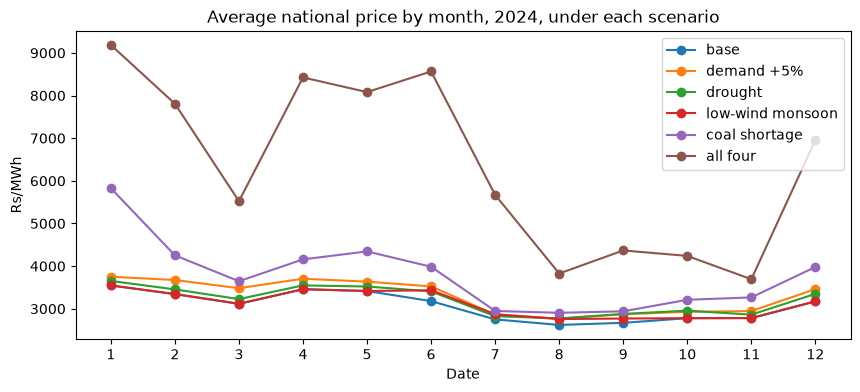

,demand +5% vs base,drought vs base,low-wind monsoon vs base,coal shortage vs base,all four vs base
Date,,,,,
1,204.0,105.0,0.0,2281.0,5639.0
2,330.0,109.0,0.0,909.0,4463.0
3,365.0,110.0,0.0,529.0,2407.0
4,246.0,89.0,0.0,700.0,4966.0
5,219.0,105.0,0.0,928.0,4665.0
6,345.0,228.0,254.0,806.0,5385.0
7,112.0,75.0,121.0,197.0,2919.0
8,148.0,153.0,138.0,285.0,1206.0
9,200.0,209.0,101.0,270.0,1697.0


In [4]:
monthly = pd.DataFrame({name: nat.Price_avg.groupby(nat.index.month).mean() for name, (st, nat) in results.items()})
monthly.plot(marker="o", figsize=(10, 4)); plt.xticks(range(1, 13)); plt.ylabel("Rs/MWh")
plt.title("Average national price by month, 2024, under each scenario"); plt.show()
(monthly.sub(monthly["base"], axis=0)).drop(columns="base").round(0).rename(columns=lambda c: c + " vs base")

In [5]:
# which states feel each shock most (change in average state price)
base_st = results["base"][0].groupby("State").Price.mean()
by_state = pd.DataFrame({name: st.groupby("State").Price.mean() - base_st
                         for name, (st, nat) in results.items() if name != "base"})
pd.concat([by_state.nlargest(5, "all four"), by_state.nsmallest(3, "all four")]).round(0)

,demand +5%,drought,low-wind monsoon,coal shortage,all four
State,,,,,
J&K(UT) & Ladakh(UT),248.0,166.0,52.0,755.0,3424.0
Chandigarh,239.0,144.0,52.0,750.0,3402.0
Haryana,239.0,144.0,52.0,750.0,3402.0
Punjab,239.0,144.0,52.0,750.0,3402.0
Uttarakhand,238.0,144.0,51.0,746.0,3387.0
Gujarat,225.0,132.0,57.0,684.0,3188.0
Chhattisgarh,224.0,129.0,49.0,704.0,3203.0
Andhra Pradesh,216.0,125.0,49.0,693.0,3203.0


## B. Step-edge price errors

For each scored day: dispatch the actual inputs with 2% more demand. If the national price rises by ≥ 100 Rs/MWh, that day sits **near a step**: a small demand error moves the price a lot.

In [6]:
SCORE = slice("2024-03-01", "2025-03-31")
dem_s = load_demand().loc[SCORE]
av_s = pd.read_csv(PROCESSED / "availability_daily.csv", parse_dates=["Date"])
lk = daily_availability_lookup(av_s[av_s.Date.between(SCORE.start, SCORE.stop)])
_, _, up = run_all_days(model, dem_s * 1.02, daily=lk)
actual_nat = pd.read_csv(PROCESSED / "dispatch_weather_national_daily.csv", parse_dates=["Date"]).set_index("Date").Price_avg.loc[SCORE]
sensitivity = up.set_index("Date").Price_avg - actual_nat
near = sensitivity >= 100
print(f"days near a step (+2% demand raises the price ≥ 100 Rs/MWh): {near.sum()} of {len(near)} ({near.mean():.0%})")

pf = pd.read_csv(PROCESSED / "price_forecast_test.csv", parse_dates=["Date"])
nat_fc = pf[(pf.Area == "National")].pivot_table(index="Date", columns=["Route", "Run"], values="Forecast")
err = pd.DataFrame({"Route B realistic": (nat_fc[("B", "realistic")] - actual_nat).abs(),
                    "persistence": (nat_fc[("B", "persistence")] - actual_nat).abs(),
                    "Route A (national LightGBM median)": (nat_fc[("A", "LightGBM median")] - actual_nat).abs()})
edge = err.groupby(near.rename("near a step")).mean().rename(index={True: "near a step", False: "far from a step"})
edge["Route B skill"] = 1 - edge["Route B realistic"] / edge["persistence"]
edge.round(1)

days near a step (+2% demand raises the price ≥ 100 Rs/MWh): 82 of 396 (21%)


,Route B realistic,persistence,Route A (national LightGBM median),Route B skill
near a step,,,,
far from a step,40.8,109.8,104.9,0.6
near a step,146.2,218.9,210.2,0.3


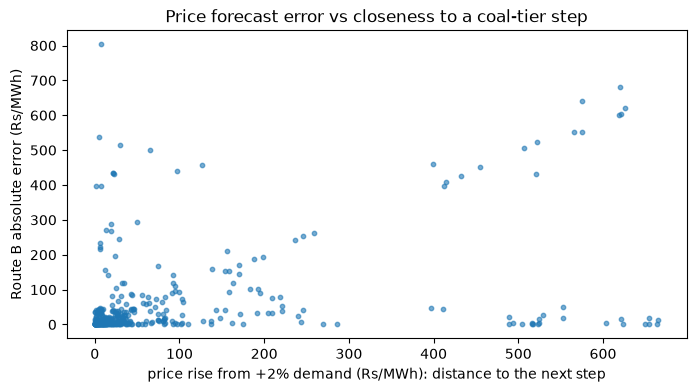

correlation: 0.39


In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(sensitivity, err["Route B realistic"], s=10, alpha=0.6)
ax.set_xlabel("price rise from +2% demand (Rs/MWh): distance to the next step")
ax.set_ylabel("Route B absolute error (Rs/MWh)")
ax.set_title("Price forecast error vs closeness to a coal-tier step")
plt.show()
print(f"correlation: {sensitivity.corr(err['Route B realistic']):.2f}")

## Save

In [8]:
out = []
for name, (st, nat) in results.items():
    out.append(nat.reset_index()[["Date", "Price_avg", "Total_cost_Rs_per_h", "Unserved_MW", "Coal_MW"]]
               .rename(columns={"Price_avg": "Price"}).assign(Area="National", Scenario=name))
    out.append(st[["Date", "State", "Price", "Unserved_MW"]].rename(columns={"State": "Area"}).assign(Scenario=name))
out = pd.concat(out, ignore_index=True)[["Date", "Area", "Scenario", "Price", "Total_cost_Rs_per_h", "Unserved_MW", "Coal_MW"]]
out.to_csv(PROCESSED / "scenario_results.csv", index=False, float_format="%.2f")
print(f"saved {len(out):,} rows")

saved 72,468 rows


## Conclusions

**A. What-ifs (2024; base average price Rs 3,069/MWh, 23% spare capacity, no shortages):**

| Scenario | Price change | Cost change | Days up a step | Unserved days | Days < 10% spare |
|---|---|---|---|---|---|
| Demand +5% | **+230 (+7.5%)** | +10.8% | 170 | 0 | 92 |
| Drought (hydro −30%) | +135 | +4.6% | 74 | 0 | 41 |
| Low-wind monsoon | +51 (June +254) | +3.2% | 30 | 0 | 18 |
| **Coal shortage (0.75 → 0.65)** | **+720 (+23%)** | +6.3% | 275 | **17 (up to 3.4 GW)** | 165 |
| **All four together** | **+3,286 (+107%)** | +35% | 363 | **156 (up to 22.6 GW)** | 313 |

- **Prices react more than demand:** 5% more demand raises the average price 7.5%, because more days climb onto a higher coal step (170 of 366 days). The supply curve is steep at the top
- **Coal is the backbone:** losing a tenth of coal availability is by far the largest single shock, and the only one that causes shortages. It hurts most in **January (+2,281 Rs/MWh)**: high winter demand, weak solar, low hydro. Renewables shocks are smaller because coal can cover them
- **Drought** costs most when reservoirs are normally full (June, September–December)
- **A weak monsoon wind** barely matters over the year (+51) but adds ~250 Rs/MWh in June
- **Shocks compound:** the four alone add up to ~1,140 Rs/MWh; together they add 3,286 and cause shortages on 156 days. Near the top of the supply curve, small extra pressures turn into scarcity: prices at the value of lost load (Rs 10,000/MWh) on some days
- **The north pays most** (J&K, Punjab, Haryana, Chandigarh, Uttarakhand: +750 in the coal shortage), being far from the coal belt and importing over longer lines; but all states move together through trade

**B. Step edges:** on **21% of days** (82 of 396) demand sits near a coal-tier step (+2% demand would raise the price ≥ 100 Rs/MWh). On those days Route B's error is **3.6× larger** (146 vs 41 Rs/MWh) and its skill halves (0.30 vs 0.60), though it still beats persistence. Error and step closeness correlate at 0.39. **Price forecast risk is concentrated on step-edge days.**

**For Part 3:** tight days are where market power bites. Today ~4% of days have less than 10% spare capacity; under one year of demand growth that rises to 25%, under a coal shortage to 45%. Step-edge days (21%) are where a small withholding of capacity moves the price most. Both are natural places to test strategic bidding.

**Limitations:** shocks are applied uniformly and all year (real droughts and coal crises are regional and seasonal); coal shortage keeps the same 0.65 for every state; the dispatch has no ramping, reserves or demand response, so scarcity shows up directly as unserved load at the value of lost load.